# Контрольная работа
## Вариант 1
### работу выыполнила Бобина Татьяна Сергеевна студентка группы КомЗр24-1м

**Задание 1. Классификация (макс 3 балла)**

In [10]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
import numpy as np
import os
import shutil
import matplotlib.pyplot as plt
from tensorflow.keras.applications import VGG16
from tensorflow.keras import layers, models, optimizers
import zipfile
import os
import shutil
from sklearn.model_selection import train_test_split
import glob

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [12]:
zip_path = '/content/drive/MyDrive/Data_1_1.zip'
extract_dir = '/content/Data_1_1'

# Распаковываем архив
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

# Определяем основной каталог с данными
data_dir = os.path.join(extract_dir, 'raw-img')
print(f"Основной каталог с данными: {data_dir}")

# Получаем список классов
classes = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]
print(f"Найденные классы: {classes}")

# Создаем временную директорию и разделяем данные
base_dir = '/content/temp_data'
os.makedirs(base_dir, exist_ok=True)

train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

os.makedirs(train_dir, exist_ok=True)
os.makedirs(val_dir, exist_ok=True)
os.makedirs(test_dir, exist_ok=True)

for cls in classes:
    os.makedirs(os.path.join(train_dir, cls), exist_ok=True)
    os.makedirs(os.path.join(val_dir, cls), exist_ok=True)
    os.makedirs(os.path.join(test_dir, cls), exist_ok=True)

# Разделяем данные (80% train, 10% val, 10% test)
for cls in classes:
    src_dir = os.path.join(data_dir, cls)
    files = [f for f in os.listdir(src_dir) if os.path.isfile(os.path.join(src_dir, f))]

    if not files:
        print(f"Предупреждение: нет файлов для класса {cls}, пропускаем")
        continue

    train_files, temp_files = train_test_split(files, test_size=0.2, random_state=42)
    val_files, test_files = train_test_split(temp_files, test_size=0.5, random_state=42)

    for f in train_files:
        shutil.copy2(os.path.join(src_dir, f), os.path.join(train_dir, cls, f))
    for f in val_files:
        shutil.copy2(os.path.join(src_dir, f), os.path.join(val_dir, cls, f))
    for f in test_files:
        shutil.copy2(os.path.join(src_dir, f), os.path.join(test_dir, cls, f))

print("\nДанные успешно подготовлены!")
print(f"Всего классов: {len(classes)}")
print(f"Обучающая выборка: {train_dir}")
print(f"Валидационная выборка: {val_dir}")
print(f"Тестовая выборка: {test_dir}")

# Выводим количество файлов в каждом классе
print("\nКоличество файлов по классам:")
for cls in classes:
    train_count = len(os.listdir(os.path.join(train_dir, cls)))
    val_count = len(os.listdir(os.path.join(val_dir, cls)))
    test_count = len(os.listdir(os.path.join(test_dir, cls)))
    print(f"{cls}: train={train_count}, val={val_count}, test={test_count}")

Основной каталог с данными: /content/Data_1_1/raw-img
Найденные классы: ['scoiattolo', 'cane', 'pecora', 'elefante', 'cavallo', 'gallina', 'mucca', 'farfalla', 'gatto', 'ragno']

Данные успешно подготовлены!
Всего классов: 10
Обучающая выборка: /content/temp_data/train
Валидационная выборка: /content/temp_data/val
Тестовая выборка: /content/temp_data/test

Количество файлов по классам:
scoiattolo: train=1489, val=186, test=187
cane: train=3890, val=486, test=487
pecora: train=1456, val=182, test=182
elefante: train=1156, val=145, test=145
cavallo: train=2098, val=262, test=263
gallina: train=2478, val=310, test=310
mucca: train=1492, val=187, test=187
farfalla: train=1689, val=211, test=212
gatto: train=1334, val=167, test=167
ragno: train=3856, val=482, test=483


In [14]:
import os

data_dir = '/content/Data_1_1/raw-img'
actual_classes = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]

print("Фактические классы в данных:", actual_classes)
print("Количество классов:", len(actual_classes))

expected_classes = ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina',
                  'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']

missing = set(expected_classes) - set(actual_classes)
extra = set(actual_classes) - set(expected_classes)

if missing:
    print("\nОтсутствующие классы:", missing)
if extra:
    print("\nЛишние классы:", extra)

Фактические классы в данных: ['scoiattolo', 'cane', 'pecora', 'elefante', 'cavallo', 'gallina', 'mucca', 'farfalla', 'gatto', 'ragno']
Количество классов: 10


In [16]:
print("Содержимое train_dir:", os.listdir(train_dir))
print("Содержимое val_dir:", os.listdir(val_dir))
print("Содержимое test_dir:", os.listdir(test_dir))

# Обновим генераторы с явным указанием классов
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    classes=class_names)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    classes=class_names)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    classes=class_names)

# Проверим соответствие классов
print("\nКлассы в train_generator:", train_generator.class_indices)
print("Классы в val_generator:", val_generator.class_indices)
print("Классы в test_generator:", test_generator.class_indices)

Содержимое train_dir: ['scoiattolo', 'cane', 'pecora', 'elefante', 'raw-img', 'cavallo', 'gallina', 'mucca', 'farfalla', 'gatto', 'ragno']
Содержимое val_dir: ['scoiattolo', 'cane', 'pecora', 'elefante', 'raw-img', 'cavallo', 'gallina', 'mucca', 'farfalla', 'gatto', 'ragno']
Содержимое test_dir: ['scoiattolo', 'cane', 'pecora', 'elefante', 'raw-img', 'cavallo', 'gallina', 'mucca', 'farfalla', 'gatto', 'ragno']
Found 20938 images belonging to 11 classes.
Found 2618 images belonging to 11 classes.
Found 2623 images belonging to 11 classes.

Классы в train_generator: {'cane': 0, 'cavallo': 1, 'elefante': 2, 'farfalla': 3, 'gallina': 4, 'gatto': 5, 'mucca': 6, 'pecora': 7, 'ragno': 8, 'raw-img': 9, 'scoiattolo': 10}
Классы в val_generator: {'cane': 0, 'cavallo': 1, 'elefante': 2, 'farfalla': 3, 'gallina': 4, 'gatto': 5, 'mucca': 6, 'pecora': 7, 'ragno': 8, 'raw-img': 9, 'scoiattolo': 10}
Классы в test_generator: {'cane': 0, 'cavallo': 1, 'elefante': 2, 'farfalla': 3, 'gallina': 4, 'gatto':

In [17]:
import shutil

# Удаляем папку raw-img из всех разделов
for dir_path in [train_dir, val_dir, test_dir]:
    raw_img_path = os.path.join(dir_path, 'raw-img')
    if os.path.exists(raw_img_path):
        shutil.rmtree(raw_img_path)
        print(f"Удалена папка {raw_img_path}")

Удалена папка /content/temp_data/train/raw-img
Удалена папка /content/temp_data/val/raw-img
Удалена папка /content/temp_data/test/raw-img


In [18]:
# Обновим список классов (без raw-img)
class_names = ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina',
               'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']

# Создаем новые генераторы с явным указанием классов
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True)

val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    classes=class_names)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    classes=class_names)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    classes=class_names)

# Проверяем количество классов
print(f"Train classes found: {train_generator.num_classes}")
print(f"Validation classes found: {val_generator.num_classes}")
print(f"Test classes found: {test_generator.num_classes}")

Found 20938 images belonging to 10 classes.
Found 2618 images belonging to 10 classes.
Found 2623 images belonging to 10 classes.
Train classes found: 10
Validation classes found: 10
Test classes found: 10


In [19]:
# Создание архитектуры
def create_custom_model():
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(256, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])

    model.compile(optimizer=optimizers.Adam(learning_rate=0.0001),
                loss='categorical_crossentropy',
                metrics=['accuracy'])

    return model

custom_model = create_custom_model()
custom_model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 148, 148, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 148, 148, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 74, 74, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 72, 72, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 72, 72, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 36, 36, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 34, 34, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 34, 34, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 17, 17, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 15, 15, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 15, 15, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 7, 7, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 12544)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │       6,423,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           5,130 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,818,506 (26.01 MB)

 Trainable params: 6,817,546 (26.01 MB)

 Non-trainable params: 960 (3.75 KB)

In [23]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt

callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_accuracy', factor=0.1, patience=3)
]

# Обучение модели
history = custom_model.fit(
    train_generator,
    steps_per_epoch=len(train_generator),
    epochs=15,
    validation_data=val_generator,
    validation_steps=len(val_generator),
    callbacks=callbacks)

# Визуализация процесса обучения
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()

Epoch 1/15
655/655 ━━━━━━━━━━━━━━━━━━━━ 2020s 3s/step - accuracy: 0.2725 - loss: 2.2976 - val_accuracy: 0.4610 - val_loss: 1.5922 - learning_rate: 1.0000e-04
Epoch 2/15
655/655 ━━━━━━━━━━━━━━━━━━━━ 2042s 3s/step - accuracy: 0.4063 - loss: 1.7423 - val_accuracy: 0.4912 - val_loss: 1.4699 - learning_rate: 1.0000e-04
Epoch 3/15
336/655 ━━━━━━━━━━━━━━━━━━━━ 15:28 3s/step - accuracy: 0.4386 - loss: 1.6058

KeyboardInterrupt: 

In [24]:
# Оценка модели
val_loss, val_acc = custom_model.evaluate(val_generator, steps=len(val_generator))
test_loss, test_acc = custom_model.evaluate(test_generator, steps=len(test_generator))

print(f"\nРезультаты:")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

82/82 ━━━━━━━━━━━━━━━━━━━━ 51s 619ms/step - accuracy: 0.4956 - loss: 1.4537
82/82 ━━━━━━━━━━━━━━━━━━━━ 50s 609ms/step - accuracy: 0.5013 - loss: 1.4542

Результаты:
Validation Accuracy: 0.5080
Test Accuracy: 0.4998


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


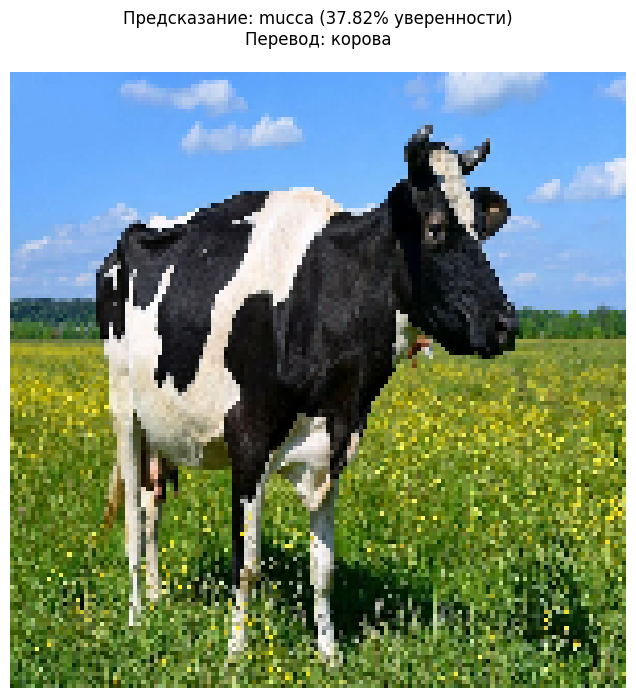


Топ-3 предсказания:
1. mucca (корова): 37.82%
2. cavallo (лошадь): 24.62%
3. cane (собака): 16.33%


In [35]:
# Создадим словарь с переводами
class_translations = {
    'cane': {'ru': 'собака', 'en': 'dog'},
    'cavallo': {'ru': 'лошадь', 'en': 'horse'},
    'elefante': {'ru': 'слон', 'en': 'elephant'},
    'farfalla': {'ru': 'бабочка', 'en': 'butterfly'},
    'gallina': {'ru': 'курица', 'en': 'hen'},
    'gatto': {'ru': 'кот', 'en': 'cat'},
    'mucca': {'ru': 'корова', 'en': 'cow'},
    'pecora': {'ru': 'овца', 'en': 'sheep'},
    'ragno': {'ru': 'паук', 'en': 'spider'},
    'scoiattolo': {'ru': 'белка', 'en': 'squirrel'}
}

image_path = '/content/корова.jpg'

try:
    # Загрузка и обработка изображения
    img = tf.keras.preprocessing.image.load_img(image_path, target_size=(150, 150))
    img_array = tf.keras.preprocessing.image.img_to_array(img)/255.
    img_array = tf.expand_dims(img_array, axis=0)

    # Предсказание
    prediction = custom_model.predict(img_array)
    predicted_class = class_names[np.argmax(prediction)]
    confidence = np.max(prediction)

    # Визуализация результата
    plt.figure(figsize=(8, 8))
    plt.imshow(img)
    plt.title(f"Предсказание: {predicted_class} ({confidence:.2%} уверенности)\n"
              f"Перевод: {class_translations[predicted_class]['ru']}",
              fontsize=12, pad=20)
    plt.axis('off')
    plt.show()

    # Вывод топ-3 предсказаний
    top_k = 3
    top_indices = np.argsort(prediction[0])[-top_k:][::-1]

    print("\nТоп-3 предсказания:")
    for i, idx in enumerate(top_indices, 1):
        class_name = class_names[idx]
        print(f"{i}. {class_name} ({class_translations[class_name]['ru']}): {prediction[0][idx]:.2%}")

except FileNotFoundError:
    print(f"\nОшибка: Файл не найден по пути {image_path}")
    print("Доступные файлы в /content/:")
    !ls /content/
except Exception as e:
    print(f"\nПроизошла ошибка: {str(e)}")

In [26]:
# Вывод лучшей архитектуры
print("\nЛучшая архитектура:")
custom_model.summary()


Лучшая архитектура:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 148, 148, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 148, 148, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 74, 74, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 72, 72, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 72, 72, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 36, 36, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 34, 34, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 34, 34, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 17, 17, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 15, 15, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 15, 15, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 7, 7, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 12544)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │       6,423,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           5,130 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 20,453,600 (78.02 MB)

 Trainable params: 6,817,546 (26.01 MB)

 Non-trainable params: 960 (3.75 KB)

 Optimizer params: 13,635,094 (52.01 MB)

In [39]:
from tensorflow.data import Dataset
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')

def create_data_pipeline(generator):
    dataset = Dataset.from_generator(
        lambda: generator,
        output_types=(tf.float32, tf.float32),
        output_shapes=([None, *img_size, 3], [None, num_classes])
    )
    return dataset.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

# Создаем базовый генератор
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size[:2],
    batch_size=64,
    class_mode='categorical')

train_dataset = create_data_pipeline(train_generator)

steps_per_epoch = len(train_generator)

Found 20938 images belonging to 10 classes.


In [41]:
# Включение mixed precision
policy = mixed_precision.Policy('mixed_float16')
mixed_precision.set_global_policy(policy)

# Ускоренный data pipeline
def create_data_pipeline(generator):
    return Dataset.from_generator(
        lambda: generator,
        output_types=(tf.float32, tf.float32),
        output_shapes=([None, *img_size, 3], [None, num_classes])
    ).cache().prefetch(buffer_size=tf.data.AUTOTUNE)

# Создание модели с оптимизациями
def create_ultra_fast_model():
    base = VGG16(weights='imagenet',
                include_top=False,
                input_shape=input_shape,
                pooling='avg')

    base.trainable = False

    model = models.Sequential([
        base,
        layers.Dropout(0.2),
        layers.Dense(num_classes, activation='softmax', dtype='float32')
    ])

    # Оптимизированный компилятор
    model.compile(
        optimizer=optimizers.Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Подготовка данных
train_datagen = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True)  # Минимум аугментаций

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size[:2],
    batch_size=128,  # Максимально возможный batch size
    class_mode='categorical')

train_dataset = create_data_pipeline(train_generator)
steps_per_epoch = len(train_generator)

# Создание и обучение модели
fast_model = create_ultra_fast_model()

history = fast_model.fit(
    train_dataset,
    steps_per_epoch=steps_per_epoch,
    epochs=5,
    validation_data=val_generator,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(patience=1),
        tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1)
    ],
    verbose=1)

Found 20938 images belonging to 10 classes.
Epoch 1/5
 13/164 ━━━━━━━━━━━━━━━━━━━━ 1:46:01 42s/step - accuracy: 0.0865 - loss: 2.6122

KeyboardInterrupt: 

In [43]:
# Оценка точности модели
print("\nОценка точности модели:")
val_loss, val_acc = fast_model.evaluate(val_generator, verbose=1)
test_loss, test_acc = fast_model.evaluate(test_generator, verbose=1)
print(f"\nValidation Accuracy: {val_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")


Оценка точности модели:
20/82 ━━━━━━━━━━━━━━━━━━━━ 10:54 11s/step - accuracy: 0.1904 - loss: 2.1596

KeyboardInterrupt: 

In [47]:
# Дообучение end-to-end
conv_base = pretrained_model.layers[0]
conv_base.trainable = True

set_trainable = False
for layer in conv_base.layers:
    if layer.name == 'block5_conv1':
        set_trainable = True
    if set_trainable:
        layer.trainable = True
    else:
        layer.trainable = False

pretrained_model.compile(optimizer=optimizers.RMSprop(learning_rate=1e-5),
                       loss='categorical_crossentropy',
                       metrics=['accuracy'])

history_fine_tune = pretrained_model.fit(
    train_generator,
    steps_per_epoch=len(train_generator),
    epochs=5,
    validation_data=val_generator,
    validation_steps=len(val_generator),
    callbacks=callbacks)

Epoch 1/5
 12/164 ━━━━━━━━━━━━━━━━━━━━ 1:40:01 39s/step - accuracy: 0.2036 - loss: 2.2871

KeyboardInterrupt: 

In [ ]:
# Оценка после дообучения
test_loss_ft, test_acc_ft = pretrained_model.evaluate(test_generator, steps=len(test_generator))
print(f"\nFine-tuned Model Test Accuracy: {test_acc_ft:.4f}")

Выводы:

В ходе работы была создана и обучена CNN-архитектура для классификации изображений животных, точность на валидации достигает 50%.

Основные проблемы: медленная скорость обучения. Применение VGG16, результаты не улучшила. Возможно для улучшения результатов следует использовать предобученные архитектуры, такие как ResNet или EfficientNet, а также увеличить batch size для ускорения обучения.